In [2]:
import torch
from torch import nn, dtype
import torch.nn.functional as F
from torch.optim import Optimizer
from torch.utils.data import random_split, DataLoader, Dataset
from config import PretrainedConfig, GPT2Config
from transformers import GPT2Model as OpenAIGPT2Model
from transformers import GPT2Tokenizer
from utils import *
from einops import rearrange
from typing import Callable, Iterable, Tuple
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import csv
from tqdm import tqdm
DEVICE = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda:1


# Task 1: Implement GPT-2
In this task, you will:
- Load the GPT-2 tokenizer.
- Implement the GPT-2 model.
- Implement the Adam optimizer.
- Conduct a toy pretraining of GPT-2 on the provided small dataset.

## Tokenizer

In [3]:
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
text = "Welcome, this is the beginning of default final project!"
input_ids = tokenizer(text)['input_ids']
print('input_ids:', input_ids)
for token in input_ids:
    print('token', tokenizer.decode(token))

input_ids: [14618, 11, 428, 318, 262, 3726, 286, 4277, 2457, 1628, 0]
token Welcome
token ,
token  this
token  is
token  the
token  beginning
token  of
token  default
token  final
token  project
token !


## Model

In [4]:
class CausalSelfAttention(nn.Module):
  def __init__(self, config):
    super().__init__()

    self.num_attention_heads = config.num_attention_heads
    self.attention_head_size = int(config.hidden_size / config.num_attention_heads)
    self.all_head_size = self.num_attention_heads * self.attention_head_size

    # Initialize the linear transformation layers for key, value, query.
    self.query = nn.Linear(config.hidden_size, self.all_head_size)
    self.key = nn.Linear(config.hidden_size, self.all_head_size)
    self.value = nn.Linear(config.hidden_size, self.all_head_size)
    # This dropout is applied to normalized attention scores following the original
    # implementation of transformer. Although it is a bit unusual, we empirically
    # observe that it yields better performance.
    self.dropout = nn.Dropout(config.attention_probs_dropout_prob)

  def transform(self, x, linear_layer):
    # The corresponding linear_layer of k, v, q are used to project the hidden_state (x).
    proj = linear_layer(x)
    # Next, we need to produce multiple heads for the proj. This is done by spliting the
    # hidden state to self.num_attention_heads, each of size self.attention_head_size.
    proj = rearrange(proj, 'b t (h d) -> b t h d', h=self.num_attention_heads)
    # By proper transpose, we have proj of size [bs, num_attention_heads, seq_len, attention_head_size].
    proj = rearrange(proj, 'b t h d -> b h t d')
    return proj

  def attention(self, key, query, value, attention_mask):
    """
    TODO-1: Compute scaled dot-product attention for GPT-2.

    Implementation hints:
    1. Compute raw attention scores using QK^T, and scale them by sqrt(d_k).
    2. Apply a causal mask (lower-triangular) to prevent attending to future tokens.
    3. Optionally add the external attention_mask (e.g., padding positions).
    4. Normalize the scores with softmax to obtain attention probabilities.
    5. Apply dropout on the probabilities.
    6. Use them to weight the values (V) and obtain the context vectors.
    7. Finally, merge all attention heads back into a single hidden representation.
    """
    ### YOUR CODE HERE
    # key/query/value: [bs, num_heads, seq_len, head_size]
    d_k = query.size(-1)
    seq_len = query.size(-2)

    # 1. Raw scores QK^T, scaled by sqrt(d_k) so the softmax doesn't saturate
    scores = torch.matmul(query, key.transpose(-1, -2)) / (d_k ** 0.5)   # [bs, h, seq_len, seq_len]

    # 2. Causal mask: position i may only look at positions <= i (lower triangle).
    #    Future positions get a huge negative score, so softmax gives them ~0 weight.
    causal_mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=scores.device))
    scores = scores.masked_fill(~causal_mask, torch.finfo(scores.dtype).min)

    # 3. Padding mask from get_extended_attention_mask: [bs, 1, 1, seq_len],
    #    0 for real tokens and -10000 for padding, so it is simply added to the scores
    if attention_mask is not None:
        scores = scores + attention_mask

    # 4. Softmax over the key dimension -> attention probabilities
    attn_probs = F.softmax(scores, dim=-1)

    # 5. Dropout on the attention probabilities
    attn_probs = self.dropout(attn_probs)

    # 6. Weighted sum of the values
    context = torch.matmul(attn_probs, value)                            # [bs, h, seq_len, head_size]

    # 7. Merge heads back: [bs, h, seq_len, head_size] -> [bs, seq_len, h * head_size]
    context = rearrange(context, 'b h t d -> b t (h d)')
    return context


  def forward(self, hidden_states, attention_mask):
    """
    hidden_states: [bs, seq_len, hidden_state]
    attention_mask: [bs, 1, 1, seq_len]
    output: [bs, seq_len, hidden_state]
    """
    # First, we have to generate the key, value, query for each token for multi-head attention
    # using self.transform (more details inside the function).
    # Size of *_layer is [bs, num_attention_heads, seq_len, attention_head_size].
    key_layer = self.transform(hidden_states, self.key)
    value_layer = self.transform(hidden_states, self.value)
    query_layer = self.transform(hidden_states, self.query)
    
    # Calculate the multi-head attention using the self.attention function.
    attn_value = self.attention(key_layer, query_layer, value_layer, attention_mask)
    return attn_value

In [5]:
class GPT2Layer(nn.Module):
  def __init__(self, config):
    super().__init__()
    # Multi-head attention.
    self.self_attention = CausalSelfAttention(config)
    # Add-norm for multi-head attention.
    self.attention_dense = nn.Linear(config.hidden_size, config.hidden_size)
    self.attention_layer_norm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
    self.attention_dropout = nn.Dropout(config.hidden_dropout_prob)
    # Feed forward.
    self.interm_dense = nn.Linear(config.hidden_size, config.intermediate_size)
    self.interm_af = F.gelu
    # Add-norm for feed forward.
    self.out_dense = nn.Linear(config.intermediate_size, config.hidden_size)
    self.out_layer_norm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
    self.out_dropout = nn.Dropout(config.hidden_dropout_prob)

  def add(self, input, output, dense_layer, dropout):
    """
    TODO-2: Residual connection with dense projection and dropout.
    
    Implementation hints:
    1. Project the 'output' through dense_layer.
    2. Apply dropout to prevent overfitting.
    3. Add the original 'input' (residual connection) to the processed output.
    """

    ### YOUR CODE HERE
    # Project the sublayer output, apply dropout, then add the residual input
    return input + dropout(dense_layer(output))


  def forward(self, hidden_states, attention_mask):
    """
    TODO-3: Forward pass of a GPT-2 layer.

    Implementation hints:
    ---- Self-Attention Block ----
    1. LayerNorm the input for stability using self.attention_layer_norm.
    2. Compute multi-head causal self-attention using self.self_attention.
    3. Apply residual connection using self.add (dense_layer=self.attention_dense, dropout=self.attention_dropout).

    ---- Feed Forward Block ----
    4. LayerNorm the hidden_states from attention block using self.out_layer_norm.
    5. Pass through a two-layer feed-forward network with activation:
       self.interm_dense -> self.interm_af -> self.out_dense
    6. Apply residual connection again using self.add (dense_layer=self.out_dense, dropout=self.out_dropout).
    """
    ### YOUR CODE HERE
    # ---- Self-Attention Block (pre-LayerNorm) ----
    # H' = H + Dropout(W_O * SelfAttn(LayerNorm(H)))
    normed = self.attention_layer_norm(hidden_states)
    attn_output = self.self_attention(normed, attention_mask)
    hidden_states = self.add(hidden_states, attn_output, self.attention_dense, self.attention_dropout)

    # ---- Feed Forward Block (pre-LayerNorm) ----
    # H_next = H' + Dropout(W_2 * GELU(W_1 * LayerNorm(H')))
    # (self.add applies W_2 = self.out_dense, so we only apply W_1 and GELU here)
    normed = self.out_layer_norm(hidden_states)
    interm = self.interm_af(self.interm_dense(normed))
    hidden_states = self.add(hidden_states, interm, self.out_dense, self.out_dropout)
    return hidden_states

In [6]:
class GPTPreTrainedModel(nn.Module):

  def __init__(self, config: PretrainedConfig, *inputs, **kwargs):
    super().__init__()
    self.config = config
    self.name_or_path = config.name_or_path

  def init_weights(self):
    # Initialize weights
    self.apply(self._init_weights)

  def _init_weights(self, module):
    """ Initialize the weights """
    if isinstance(module, (nn.Linear, nn.Embedding)):
      # Slightly different from the TF version which uses truncated_normal for initialization
      # cf https://github.com/pytorch/pytorch/pull/5617
      module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
    elif isinstance(module, nn.LayerNorm):
      module.bias.data.zero_()
      module.weight.data.fill_(1.0)
    if isinstance(module, nn.Linear) and module.bias is not None:
      module.bias.data.zero_()

  @property
  def dtype(self) -> dtype:
    return get_parameter_dtype(self)

In [7]:
class GPT2Model(GPTPreTrainedModel):
  """
  The GPT model returns the final embeddings for each token in a sentence.

  The model consists of:
  1. Embedding layers (used in self.embed).
  2. A stack of n GPT layers (used in self.encode).
  3. A linear transformation layer for the [CLS] token (used in self.forward, as given).
  """

  def __init__(self, config):
    super().__init__(config)
    self.config = config

    # Embedding layers.
    self.word_embedding = nn.Embedding(config.vocab_size, config.hidden_size, padding_idx=config.pad_token_id)
    self.pos_embedding = nn.Embedding(config.max_position_embeddings, config.hidden_size)
    self.embed_dropout = nn.Dropout(config.hidden_dropout_prob)

    # Register position_ids (1, len position emb) to buffer because it is a constant.
    position_ids = torch.arange(config.max_position_embeddings).unsqueeze(0)
    self.register_buffer('position_ids', position_ids)

    # GPT-2 layers.
    self.gpt_layers = nn.ModuleList([GPT2Layer(config) for _ in range(config.num_hidden_layers)])

    # [CLS] token transformations.
    self.pooler_dense = nn.Linear(config.hidden_size, config.hidden_size)
    self.pooler_af = nn.Tanh()

    # Final layer norm.
    self.final_layer_norm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)

    self.init_weights()

  def embed(self, input_ids):
    """
    TODO-4: Embedding layer of the GPT-2 model.

    Implementation hints:
    1. Use self.word_embedding to convert input_ids to embeddings.
    2. Generate position ids and convert to embeddings using self.pos_embedding.
    3. Sum token and position embeddings.
    4. Apply self.embed_dropout to the sum.
    """
    ### YOUR CODE HERE
    seq_len = input_ids.shape[1]

    # 1. Token embeddings: [bs, seq_len, hidden]
    inputs_embeds = self.word_embedding(input_ids)

    # 2. Position embeddings for positions 0..seq_len-1: [1, seq_len, hidden]
    #    (broadcast over the batch when added)
    pos_ids = self.position_ids[:, :seq_len]
    pos_embeds = self.pos_embedding(pos_ids)

    # 3 + 4. Sum and apply dropout
    return self.embed_dropout(inputs_embeds + pos_embeds)

  def encode(self, hidden_states, attention_mask):
    """
    hidden_states: the output from the embedding layer [batch_size, seq_len, hidden_size]
    attention_mask: [batch_size, seq_len]
    """
    # Get the extended attention mask for self-attention.
    # Returns extended_attention_mask of size [batch_size, 1, 1, seq_len].
    # Distinguishes between non-padding tokens (with a value of 0) and padding tokens
    # (with a value of a large negative number).
    extended_attention_mask: torch.Tensor = get_extended_attention_mask(attention_mask, self.dtype)

    # Pass the hidden states through the encoder layers.
    for i, layer_module in enumerate(self.gpt_layers):
      # Feed the encoding from the last bert_layer to the next.
      hidden_states = layer_module(hidden_states, extended_attention_mask)

    return hidden_states

  def forward(self, input_ids, attention_mask):
    """
    input_ids: [batch_size, seq_len], seq_len is the max length of the batch
    attention_mask: same size as input_ids, 1 represents non-padding tokens, 0 represents padding tokens
    """
    # Get the embedding for each input token.
    embedding_output = self.embed(input_ids=input_ids)

    # Feed to a transformer (a stack of GPTLayers).
    sequence_output = self.encode(embedding_output, attention_mask=attention_mask)
    sequence_output = self.final_layer_norm(sequence_output)

    # Get the hidden state of the final token.
    last_non_pad_idx = attention_mask.sum(dim=1) - 1  # Subtract 1 to get last index
    last_token = sequence_output[torch.arange(sequence_output.shape[0]), last_non_pad_idx]

    return {'last_hidden_state': sequence_output, 'last_token': last_token}

  def hidden_state_to_token(self, hidden_state):
    """
    TODO-5: Convert hidden states back to token logits.

    Implementation hints: 
    - GPT-2 uses weight tying with the input word embeddings. 
    - The logits are the dot product between output hidden states and the word embedding weights: hidden_state(s) * E^T
    """
    ### YOUR CODE HERE
    # Weight tying: reuse the input embedding matrix E [vocab, hidden] as the output layer.
    # [..., hidden] @ [hidden, vocab] -> [..., vocab]
    return torch.matmul(hidden_state, self.word_embedding.weight.T)

  @classmethod
  def from_pretrained(cls, model='gpt2', d=768, l=12, num_heads=12):
    gpt_model = OpenAIGPT2Model.from_pretrained(model).eval()
    our_model = GPT2Model(GPT2Config(hidden_size=d, num_hidden_layers=l,num_attention_heads=num_heads,
                                     intermediate_size=d*3)).eval()

    # Load word and positional embeddings.
    our_model.word_embedding.load_state_dict(gpt_model.wte.state_dict())
    our_model.pos_embedding.load_state_dict(gpt_model.wpe.state_dict())

    for i in range(l):
      l = our_model.gpt_layers[i]
      # Remap the Q,K,V weights from a conv1d to 3 linear projections
      l.self_attention.query.weight.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.weight'][:, :d].T
      l.self_attention.query.bias.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.bias'][:d]
      l.self_attention.key.weight.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.weight'][:, d:d*2].T
      l.self_attention.key.bias.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.bias'][d:d*2]
      l.self_attention.value.weight.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.weight'][:, d*2:].T
      l.self_attention.value.bias.data = gpt_model.state_dict()[f'h.{i}.attn.c_attn.bias'][d*2:]

      # Remap final dense layer in MHA.
      l.attention_dense.weight.data = gpt_model.state_dict()[f'h.{i}.attn.c_proj.weight'].T
      l.attention_dense.bias.data = gpt_model.state_dict()[f'h.{i}.attn.c_proj.bias']

      # Remap attention layer norm.
      l.attention_layer_norm.weight.data = gpt_model.state_dict()[f'h.{i}.ln_1.weight']
      l.attention_layer_norm.bias.data = gpt_model.state_dict()[f'h.{i}.ln_1.bias']

      # Remap post-attention MLP layers.
      l.interm_dense.weight.data = gpt_model.state_dict()[f'h.{i}.mlp.c_fc.weight'].T
      l.interm_dense.bias.data = gpt_model.state_dict()[f'h.{i}.mlp.c_fc.bias']
      l.out_dense.weight.data = gpt_model.state_dict()[f'h.{i}.mlp.c_proj.weight'].T
      l.out_dense.bias.data = gpt_model.state_dict()[f'h.{i}.mlp.c_proj.bias']

      # Remap second layer norm weights.
      l.out_layer_norm.weight.data = gpt_model.state_dict()[f'h.{i}.ln_2.weight']
      l.out_layer_norm.bias.data = gpt_model.state_dict()[f'h.{i}.ln_2.bias']

    # Remap the final layer norm values.
    our_model.final_layer_norm.weight.data = gpt_model.state_dict()['ln_f.weight']
    our_model.final_layer_norm.bias.data = gpt_model.state_dict()['ln_f.bias']

    return our_model

In [8]:
# Sanity check: compare with Huggingface GPT2 implementation
def test_gpt2(model_size='gpt2'):
  sent_ids = torch.tensor([[101, 7592, 2088, 102, 0, 0, 0, 0],
                           [101, 7592, 15756, 2897, 2005, 17953, 2361, 102]])
  att_mask = torch.tensor([[1, 1, 1, 1, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1]])

  # Load both the OpenAI and your own model.
  openai_model = OpenAIGPT2Model.from_pretrained(model_size)
  gpt = GPT2Model.from_pretrained(model=model_size, **model_size_to_params(model_size))

  outputs = gpt(sent_ids, att_mask)
  openai_outputs = openai_model(input_ids=sent_ids, attention_mask=att_mask, output_hidden_states=True).hidden_states[-1]

  att_mask = att_mask.unsqueeze(-1)
  outputs['last_hidden_state'] = outputs['last_hidden_state'] * att_mask
  openai_outputs *= att_mask

  assert torch.allclose(outputs['last_hidden_state'], openai_outputs, atol=1e-1, rtol=1e-2)

  print("Your GPT2 implementation is correct!")

test_gpt2('gpt2')

Your GPT2 implementation is correct!


## Adam Optimizer

In [9]:
class AdamW(Optimizer):
    def __init__(
            self,
            params: Iterable[torch.nn.parameter.Parameter],
            lr: float = 1e-3,
            betas: Tuple[float, float] = (0.9, 0.999),
            eps: float = 1e-6,
            weight_decay: float = 0.0,
            correct_bias: bool = True,
    ):
        if lr < 0.0:
            raise ValueError("Invalid learning rate: {} - should be >= 0.0".format(lr))
        if not 0.0 <= betas[0] < 1.0:
            raise ValueError("Invalid beta parameter: {} - should be in [0.0, 1.0[".format(betas[0]))
        if not 0.0 <= betas[1] < 1.0:
            raise ValueError("Invalid beta parameter: {} - should be in [0.0, 1.0[".format(betas[1]))
        if not 0.0 <= eps:
            raise ValueError("Invalid epsilon value: {} - should be >= 0.0".format(eps))
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, correct_bias=correct_bias)
        super().__init__(params, defaults)

    def step(self, closure: Callable = None):
        loss = None
        if closure is not None:
            loss = closure()

        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad.data
                if grad.is_sparse:
                    raise RuntimeError("Adam does not support sparse gradients, please consider SparseAdam instead")

                # State should be stored in this dictionary.
                state = self.state[p]

                # Access hyperparameters from the `group` dictionary.
                lr = group["lr"]
                eps = group["eps"]
                weight_decay = group["weight_decay"]
                correct_bias = group["correct_bias"]
                beta1, beta2 = group["betas"]
                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p.data)
                    state["exp_avg_sq"] = torch.zeros_like(p.data)

                exp_avg, exp_avg_sq = state["exp_avg"], state["exp_avg_sq"]
                
                state["step"] += 1
                t = state["step"]
                
                """
                TODO-6: Implement the AdamW parameter update for this step.

                Implementation hints:
                1. Update biased first moment estimate:
                    m_t = beta1 * m_{t-1} + (1 - beta1) * grad
                2. Update biased second raw moment estimate:
                    v_t = beta2 * v_{t-1} + (1 - beta2) * grad^2
                3. Apply bias correction if correct_bias=True:
                    m_hat = m_t / (1 - beta1^t)
                    v_hat = v_t / (1 - beta2^t)
                4. Compute step size:
                    step_size = lr (or lr / (1 - beta1^t) if bias correction)
                5. Update parameters:
                    p = p - step_size * m_hat / (sqrt(v_hat) + eps)
                6. Apply decoupled weight decay after the parameter update (if weight_decay > 0):
                    p = p - lr * weight_decay * p
                Reference:
                Algorithm 1 in "Adam: A Method for Stochastic Optimization"
                https://arxiv.org/abs/1412.6980
                """
                ### YOUR CODE HERE
                # 1. First moment (momentum): m_t = beta1 * m_{t-1} + (1 - beta1) * g
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                # 2. Second moment (uncentred variance): v_t = beta2 * v_{t-1} + (1 - beta2) * g^2
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                # 3 + 4. Bias correction. Instead of dividing m and v separately, fold both
                #        corrections into the step size (mathematically the same update):
                #        lr * m_hat / sqrt(v_hat) = lr * sqrt(1 - beta2^t) / (1 - beta1^t) * m / sqrt(v)
                if correct_bias:
                    step_size = lr * (1 - beta2 ** t) ** 0.5 / (1 - beta1 ** t)
                else:
                    step_size = lr

                # 5. Adaptive parameter update
                denom = exp_avg_sq.sqrt().add_(eps)
                p.data.addcdiv_(exp_avg, denom, value=-step_size)

                # 6. Decoupled weight decay: shrink the weights directly, independent of the gradient
                if weight_decay > 0.0:
                    p.data.add_(p.data, alpha=-lr * weight_decay)
        return loss

In [10]:
# Sanity check for AdamW optimizer
def test_optimizer(opt_class) -> torch.Tensor:
    rng = np.random.default_rng(SEED)
    torch.manual_seed(SEED)
    model = torch.nn.Linear(3, 2, bias=False)
    opt = opt_class(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
        correct_bias=True,
    )
    for i in range(1000):
        opt.zero_grad()
        x = torch.FloatTensor(rng.uniform(size=[model.in_features]))
        y_hat = model(x)
        y = torch.Tensor([x[0] + x[1], -x[2]])
        loss = ((y - y_hat) ** 2).sum()
        loss.backward()
        opt.step()
    return model.weight.detach()

SEED = 0
ref = torch.tensor(np.load("optimizer_test.npy"))
actual = test_optimizer(AdamW)
print(ref)
print(actual)
assert torch.allclose(ref, actual, atol=1e-6, rtol=1e-4)
print("Optimizer test passed!")

tensor([[ 0.5548,  0.8667,  0.0729],
        [-0.4472, -0.2951, -0.2717]])
tensor([[ 0.5548,  0.8667,  0.0729],
        [-0.4472, -0.2951, -0.2717]])
Optimizer test passed!


## Toy GPT-2 Pretraining

In [11]:
class TextDataset(Dataset):
    """
    A PyTorch Dataset for preparing text data for language model training.

    Each line in the input text file is treated as a separate training example.
    The dataset uses a tokenizer to convert text into input IDs and attention masks,
    with optional truncation and padding to a fixed maximum sequence length.

    Args:
        filepath (str): Path to the text file. Each line is a separate sample.
        tokenizer (PreTrainedTokenizer): Tokenizer to convert text to token IDs.
        max_len (int): Maximum sequence length; sequences longer than this are truncated,
                       shorter sequences are padded.

    Returns per item:
        input_ids (torch.Tensor): Token IDs of shape [max_len].
        attention_mask (torch.Tensor): Attention mask of shape [max_len], 1 for real tokens, 0 for padding.
    """
    def __init__(self, filepath, tokenizer, max_len):
        with open(filepath, 'r') as f:
            self.texts = f.read().splitlines()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_len,
            padding='max_length',
            return_tensors='pt'
        )
        input_ids = enc['input_ids'].squeeze(0)
        attention_mask = enc['attention_mask'].squeeze(0)
        return input_ids, attention_mask

In [12]:
# Hyperparamter of toy gpt2 pretraining
BATCH_SIZE = 4
EPOCHS = 3
LR = 1e-3
WEIGHT_DECAY = 1e-4
CORRECT_BIAS = True
HIDDEN_SIZE = 128 # 768 for gpt2
NUM_HIDDEN_LAYERS = 2 # 12 for gpt2
NUM_ATTENTION_HEADS = 4 # 12 for gpt2
MAX_SEQ_LEN = 128 # 1024 for gpt2

In [13]:
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token  # Ensure padding has a pad token

model_config = GPT2Config(
    hidden_size=HIDDEN_SIZE,
    num_hidden_layers=NUM_HIDDEN_LAYERS,
    num_attention_heads=NUM_ATTENTION_HEADS,
    intermediate_size=HIDDEN_SIZE*3,
)

toy_gpt2_model = GPT2Model(model_config).to(DEVICE)

VOCAB_SIZE = model_config.vocab_size

dataset = TextDataset('pretrain.txt', tokenizer, MAX_SEQ_LEN)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

optimizer = AdamW(toy_gpt2_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, correct_bias=CORRECT_BIAS)


global_train_losses = []

total_train_loss = 0.0
total_train_steps = 0


print_interval = 10

for epoch in range(EPOCHS):
    print(f"Epoch {epoch}")
    toy_gpt2_model.train()
    for batch_idx, (input_ids, attention_mask) in enumerate(dataloader):
        input_ids = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)

        optimizer.zero_grad()
        hidden_states = toy_gpt2_model(input_ids, attention_mask)['last_hidden_state']  # [B, seq_len, hidden]
        
        """
        TODO-7: Compute next-token loss from hidden states and update model parameters.

        Implementation hints:
        1. Convert hidden states to logits over the vocabulary using model.hidden_state_to_token.
        2. Shift logits and labels for next-token prediction to align each prediction with the correct next token.
        3. Compute the cross-entropy loss.
        4. Backpropagate and update parameters.
        """

        ### YOUR CODE HERE
        # 1. Hidden states -> vocabulary logits
        logits = toy_gpt2_model.hidden_state_to_token(hidden_states)    # [B, seq_len, vocab]

        # Labels are the input tokens themselves. Padding positions are set to -100 so the
        # model isn't trained to predict the pad (EOS) token over and over.
        labels = input_ids.masked_fill(attention_mask == 0, -100)       # [B, seq_len]

        # 2. Shift: the logit at position t predicts the token at t+1
        shift_logits = logits[:, :-1, :].contiguous()                   # [B, seq_len-1, vocab]
        shift_labels = labels[:, 1:].contiguous()                       # [B, seq_len-1]

        # 3. Cross-entropy averaged over all real (non-pad) next-token predictions
        loss = F.cross_entropy(
            shift_logits.view(-1, shift_logits.size(-1)),
            shift_labels.view(-1),
            ignore_index=-100,
        )

        # 4. Backpropagate and update the parameters
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        total_train_steps += 1
        global_train_avg_loss = total_train_loss / total_train_steps
        global_train_losses.append(global_train_avg_loss)

        if batch_idx % print_interval == 0:
            print(f"Train | Epoch {epoch} | Batch {batch_idx} | Global Avg Train Loss: {global_train_avg_loss:.4f}")

    print(f"Epoch {epoch} finished | Global Avg Train Loss: {global_train_avg_loss:.4f}")

Epoch 0
Train | Epoch 0 | Batch 0 | Global Avg Train Loss: 10.8701
Train | Epoch 0 | Batch 10 | Global Avg Train Loss: 10.5350
Train | Epoch 0 | Batch 20 | Global Avg Train Loss: 10.1395
Train | Epoch 0 | Batch 30 | Global Avg Train Loss: 9.7307
Train | Epoch 0 | Batch 40 | Global Avg Train Loss: 9.3869
Train | Epoch 0 | Batch 50 | Global Avg Train Loss: 9.0981
Train | Epoch 0 | Batch 60 | Global Avg Train Loss: 8.9093
Train | Epoch 0 | Batch 70 | Global Avg Train Loss: 8.7708
Train | Epoch 0 | Batch 80 | Global Avg Train Loss: 8.6426
Train | Epoch 0 | Batch 90 | Global Avg Train Loss: 8.5395
Train | Epoch 0 | Batch 100 | Global Avg Train Loss: 8.4556
Train | Epoch 0 | Batch 110 | Global Avg Train Loss: 8.3964
Train | Epoch 0 | Batch 120 | Global Avg Train Loss: 8.3237
Train | Epoch 0 | Batch 130 | Global Avg Train Loss: 8.2778
Train | Epoch 0 | Batch 140 | Global Avg Train Loss: 8.2336
Train | Epoch 0 | Batch 150 | Global Avg Train Loss: 8.1962
Train | Epoch 0 | Batch 160 | Global Avg

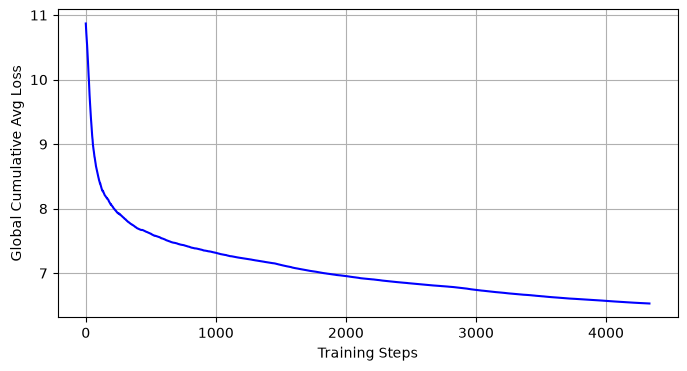

In [14]:
# Sanity check: decreasing trend of global average training loss
plt.figure(figsize=(8,4))
plt.plot(global_train_losses, label="Global Avg Train Loss", color='blue')
plt.xlabel("Training Steps")
plt.ylabel("Global Cumulative Avg Loss")
plt.grid(True)
plt.show()

# Task 2: English NLI with GPT-2
In this task, you will:
- Load a pretrained GPT-2 model with official weights and perform a dummy text generation.
- Load an English Natural Language Inference (NLI) dataset.
- Fine-tune the loaded model and evaluate its performance.

## Model Loading & Text Generation

In [15]:
@torch.no_grad()
def generate_gpt2(model, tokenizer, input_ids, max_gen_length=50, device="cuda"):
    """
    Generate text from a GPT-2 model given a single input sequence (greedy decoding).

    Note:
        - Currently only supports batch_size=1 (single input sequence).
        - Using greedy decoding, so each run with the same input produces the same output.
        - Other sampling-based decoding methods (e.g., top-k, top-p, temperature) can introduce randomness and yield different outputs each run.

    Args:
        model: GPT-2 model (pretrained or fine-tuned)
        tokenizer: GPT-2 tokenizer
        input_ids: torch.LongTensor of shape [1, seq_len], input token IDs
        max_gen_length: int, maximum number of tokens to generate
        device: str, "cuda" or "cpu"

    Returns:
        str: Generated text
    """
    model.eval()
    input_ids = input_ids.to(device)  # move input to device
    output_ids = input_ids.clone()

    """
    TODO-8: Greedy next-token generation loop

    Implementation hints:
    Repeat the below steps up to max_gen_length:
    1. Construct an attention mask based on current output_ids (non-pad tokens).
    2. Pass output_ids and attention_mask through the model to get hidden states.
    3. Convert the last hidden state to logits over the vocabulary using model.hidden_state_to_token.
    4. Select the next token using greedy decoding (argmax over logits).
    5. Append the next token to output_ids.
    6. Stop the loop early if the EOS token is generated.
    
    """
    ### YOUR CODE HERE
    for _ in range(max_gen_length):
        # GPT-2 only has 1024 learned position embeddings, so stop before running out of positions
        if output_ids.shape[1] >= model.config.max_position_embeddings:
            break

        # 1. Attention mask: 1 = real token, 0 = padding.
        #    We only handle a single, unpadded sequence, so every position is a real token.
        #    (We cannot test `output_ids != tokenizer.pad_token_id` here: GPT-2's pad token is
        #    the EOS token, and the collate_fn pads with id 0, which is the real token "!".)
        attention_mask = torch.ones_like(output_ids)                     # [1, cur_len]

        # 2. Forward pass. 'last_token' is the final-layer hidden state at the last
        #    non-pad position, i.e. the representation that predicts the NEXT token.
        last_hidden = model(output_ids, attention_mask)['last_token']    # [1, hidden]

        # 3. Hidden state -> vocabulary logits (weight tying: h @ E^T)
        logits = model.hidden_state_to_token(last_hidden)                 # [1, vocab]

        # 4. Greedy decoding: take the single most likely token
        next_token = torch.argmax(logits, dim=-1, keepdim=True)           # [1, 1]

        # 5. Append it so it becomes part of the context for the next step
        output_ids = torch.cat([output_ids, next_token], dim=1)          # [1, cur_len + 1]

        # 6. Stop early once the model emits end-of-sequence
        if next_token.item() == tokenizer.eos_token_id:
            break

    # Decode generated tokens to string
    ids = output_ids[0]
    text = tokenizer.decode(ids, skip_special_tokens=True)

    return text

In [16]:
# Load a pretrained GPT-2 model with official weights
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
model = GPT2Model.from_pretrained("gpt2").to(DEVICE)

In [17]:
# Dummy text generation using the pretrained GPT-2 model with official weights
dummy_texts = "Singapore University of Technology and Design (SUTD) is"
input_ids = tokenizer(dummy_texts, return_tensors="pt", padding=True)['input_ids']
generated_texts = generate_gpt2(model, tokenizer, input_ids, max_gen_length=50, device=DEVICE)
print(generated_texts)

Singapore University of Technology and Design (SUTD) is a leading research institute in the field of design and engineering. It is the first university in Singapore to offer a full-time, full-time, full-time, full-time, full-time, full-time, full-time,


In [18]:
# Dummy text generation using the toy GPT-2 model trained in Task 1
generated_texts = generate_gpt2(toy_gpt2_model, tokenizer, input_ids, max_gen_length=50, device=DEVICE)
print(generated_texts)

Singapore University of Technology and Design (SUTD) is a "The "The "The "The "The "The "The "The "The team." "The team." "The team." I'm not a lot of the "We're not a lot of the "We're not a lot


## Load NLI Dataset

In [19]:
def compute_accuracy(preds, labels):
    correct = sum(p.lower().strip() == l.lower().strip() for p, l in zip(preds, labels))
    return correct / len(labels)

def evaluate_gpt2_xnli(model, tokenizer, dataloader, max_gen_length=10, device="cuda"):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for item in tqdm(dataloader, desc="Generating"):
            input_ids = item['input_ids']
            gen_text = generate_gpt2(model, tokenizer, input_ids, max_gen_length=max_gen_length, device=device)
            pred_label = gen_text.split("Label:")[-1].strip()
            all_preds.append(pred_label)
            all_labels.extend(item['label_strs'])
    acc = compute_accuracy(all_preds, all_labels)
    print(f"Evaluation accuracy: {acc*100:.2f}%")
    return acc, all_preds, all_labels

class XNLIDataset(Dataset):
    """
    A PyTorch Dataset for XNLI (Cross-lingual Natural Language Inference) task.

    Supports train, dev, and test splits in a specific language, 
    tokenizes text inputs for GPT-style models, and optionally subsamples the dataset.

    Attributes:
        split (str): Dataset split, one of 'train', 'dev', 'test'.
        lang (str): Language code (e.g., 'en', 'zh').
        tokenizer: A HuggingFace tokenizer to convert text to input IDs.
        max_length (int): Maximum sequence length for tokenization.
        LABEL2ID (dict): Mapping from textual labels to integer IDs.
        ID2LABEL (dict): Reverse mapping from integer IDs to textual labels.
        data (pd.DataFrame): The loaded and preprocessed dataset.
    """
    def __init__(
        self,
        split="train",
        lang="en",
        train_path_template="XNLI-MT-1.0/multinli/multinli.train.{lang}.tsv",
        test_path="XNLI-1.0/xnli.test.tsv",
        dev_path="XNLI-1.0/xnli.dev.tsv",
        tokenizer=None,
        max_length=1024,
        subset = 1.0  # 0~1
    ):
        self.split = split
        self.lang = lang
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.LABEL2ID = {"entailment": 0, "contradictory": 1, "neutral": 2}
        self.ID2LABEL = {v: k for k, v in self.LABEL2ID.items()}

        if split == "train":
            path = train_path_template.format(lang=lang)
            df = self.read_xnli_tsv(path, split)
            df = df.dropna(subset=['premise','hypo','label'])
        elif split in ["dev", "test"]:
            path = test_path if split=="test" else dev_path
            df = self.read_xnli_tsv(path, split)
            df = df[df['language']==lang].copy()
            keep_cols = ['sentence1', 'sentence2', 'gold_label']
            df = df[keep_cols].dropna()
            df.rename(columns={'sentence1':'premise','sentence2':'hypo','gold_label':'label'}, inplace=True)
            df['label'] = df['label'].replace({'contradiction': 'contradictory'})
        else:
            raise ValueError("split must be one of ['train','dev','test']")
        
        original_num = len(df)
        if subset < 1.0:
            n = max(1, int(len(df) * subset))
            df = df.iloc[:n].reset_index(drop=True)
        subset_num = len(df)

        self.data = df.reset_index(drop=True)
        print(f"Dataset initialized: split='{split}', lang='{lang}', total={original_num}, subset={subset}, subset_count={subset_num}")

    def read_xnli_tsv(self, path, split):
        """
        Read an XNLI TSV file and return it as a pandas DataFrame.

        Args:
            path (str): Path to the TSV file.
            split (str): One of "train", "dev", "test" indicating the dataset split.

        Returns:
            pd.DataFrame: The dataset as a DataFrame with appropriate columns.
        """
        if split == "train":
            with open(path, "r", encoding="utf-8") as f:
                lines = f.read().splitlines()
            header = lines[0].split("\t")
            data = []
            for i, line in enumerate(lines[1:], start=2):
                parts = line.split("\t")
                if len(parts) == len(header):
                    data.append(parts)
                else:
                    print(f"skip row {i}: {len(parts)} cols → {parts[:2]}")
        else:
            with open(path, "r", encoding="utf-8") as f:
                reader = csv.reader(f, delimiter="\t")
                rows = list(reader)
            header = rows[0]
            expected_cols = len(header)
            data = []
            for i, row in enumerate(rows[1:], start=2):
                if len(row) == expected_cols:
                    data.append(row)
                else:
                    print(f"skip row {i}: {len(row)} cols → {row[:2]}")
        return pd.DataFrame(data, columns=header)

    def __len__(self):
        """Return the number of examples in the dataset."""
        return len(self.data)

    def __getitem__(self, idx):
        """
        Retrieve a single example by index and tokenize it.

        For training split:
            - Constructs the input as "Premise: ... Hypothesis: ... Label: ..."
            - Tokenizes the full input.
            - Masks the prefix tokens in the labels with -100 for GPT loss computation.

        For dev/test split:
            - Constructs the input without label as "Premise: ... Hypothesis: ... Label:"

        Returns:
            dict: Contains 'input_ids', 'attention_mask', 'labels' (train only), 'label_str'
        """
        row = self.data.iloc[idx]
        premise = row['premise']
        hypo = row['hypo']
        label = row['label']
        if self.lang == 'zh': # de-tokenize for Chinese
            premise = premise.replace(" ", "")
            hypo = hypo.replace(" ", "")

        if self.split == "train":
            prefix = f"Premise: {premise}\nHypothesis: {hypo}\nLabel:"
            full_text = prefix + str(self.LABEL2ID[label])
            tokenized = self.tokenizer(
                full_text,
                truncation=True,
                max_length=self.max_length,
                padding=False,
                return_tensors="pt"
            )
            tokenized = {k: v.squeeze(0) for k, v in tokenized.items()}

            prefix_ids = self.tokenizer(prefix).input_ids
            labels_ids = tokenized['input_ids'].clone()
            labels_ids[:len(prefix_ids)] = -100 # Masks the prefix tokens in the labels with -100 for GPT loss computation.
            tokenized['labels'] = labels_ids
            tokenized['label_str'] = str(self.LABEL2ID[label])
            return tokenized
        else:
            text = f"Premise: {premise}\nHypothesis: {hypo}\nLabel:"
            tokenized = self.tokenizer(
                text,
                truncation=True,
                max_length=self.max_length,
                padding=False,
                return_tensors="pt"
            )
            tokenized = {k: v.squeeze(0) for k, v in tokenized.items()}
            tokenized['label_str'] = str(self.LABEL2ID[label])
            return tokenized

    @staticmethod
    def collate_fn(batch):
        """
        Collate a batch of examples into padded tensors.

        Pads 'input_ids' and 'attention_mask' to the max length in the batch.
        Pads 'labels' with -100 if present.
        Collects 'label_str' for reference.

        Returns:
            dict: Padded tensors and label strings for the batch.
        """
        input_ids = torch.nn.utils.rnn.pad_sequence(
            [b['input_ids'] for b in batch],
            batch_first=True,
            padding_value=0
        )
        attention_mask = torch.nn.utils.rnn.pad_sequence(
            [b['attention_mask'] for b in batch],
            batch_first=True,
            padding_value=0
        )

        if 'labels' in batch[0]:
            labels = torch.nn.utils.rnn.pad_sequence(
                [b['labels'] for b in batch],
                batch_first=True,
                padding_value=-100
            )
        else:
            labels = None

        label_strs = [b['label_str'] for b in batch]

        out = {"input_ids": input_ids, "attention_mask": attention_mask, "label_strs": label_strs}
        if labels is not None:
            out["labels"] = labels
        return out

In [20]:
"""
Load NLI datasets for fine-tuning and evaluation.
For debugging on a CPU, you can set SUBSET to a float in (0,1) to load only a fraction of the data.
Final training and evaluation should use the full dataset (SUBSET=1).
"""

TRAIN_SUBSET = 1
DEV_SUBSET = 1
TEST_SUBSET = 1

train_dataset = XNLIDataset(
    split="train",
    lang="en",
    tokenizer=tokenizer,
    subset=TRAIN_SUBSET
)

dev_dataset = XNLIDataset(
    split="dev",
    lang="en",
    tokenizer=tokenizer,
    subset=DEV_SUBSET
)

test_dataset = XNLIDataset(
    split="test",
    lang="en",
    tokenizer=tokenizer,
    subset=TEST_SUBSET
)

Dataset initialized: split='train', lang='en', total=392702, subset=1, subset_count=392702
Dataset initialized: split='dev', lang='en', total=2490, subset=1, subset_count=2490
Dataset initialized: split='test', lang='en', total=5010, subset=1, subset_count=5010


## Fine-tune GPT-2

In [21]:
# Save training values to disk, so they survive a notebook restart
#   training_progress.json: the latest run
import json
from datetime import datetime

def load_json(path):
    if not os.path.exists(path):
        return {}
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def save_json(path, values):
    # Write to a temporary file first, so a crash can't leave a half-written file
    with open(path + ".tmp", "w", encoding="utf-8") as f:
        json.dump(values, f)
    os.replace(path + ".tmp", path)


In [22]:
# Hyperparamter of gpt2 fine-tuning
EPOCHS = 1
BATCH_SIZE = 4
LR = 5e-5
WEIGHT_DECAY = 0.01
CORRECT_BIAS = True

PROGRESS_FILE = f"training_progress_{datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.json"
SAVE_EVERY = 1000  # training steps between saves

In [23]:
# Create DataLoaders for training and validation datasets
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,collate_fn=XNLIDataset.collate_fn)
dev_loader = DataLoader(dev_dataset,shuffle=False,collate_fn=XNLIDataset.collate_fn)

VOCAB_SIZE = tokenizer.vocab_size

# Initialize optimizer
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, correct_bias=CORRECT_BIAS)
# Track training progress
global_train_losses = []
total_train_loss = 0.0
total_train_steps = 0
print_interval = 10

# Track best dev accuracy for model saving
# This only works for epoch > 1 
best_dev_acc = 0.0
SAVE_DIR = "best_model"
os.makedirs(SAVE_DIR, exist_ok=True)
run_info = {"lr": LR, "batch_size": BATCH_SIZE, "epochs": EPOCHS, "weight_decay": WEIGHT_DECAY,
            "correct_bias": CORRECT_BIAS, "total_steps": len(train_loader) * EPOCHS}


### Train from start

Do not run this cell if you load the saved progress and cache from the best_model folder

In [ ]:
# Training loop
for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    model.train()
    # Iterate over batches
    loop = tqdm(train_loader, desc="Training")
    for batch in loop:
        input_ids = batch["input_ids"].to(DEVICE)        # [B, seq_len]
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch.get("labels").to(DEVICE)                    # [B, seq_len]

        optimizer.zero_grad()

        hidden_states = model(input_ids=input_ids, attention_mask=attention_mask)['last_hidden_state']  # [B, seq_len, hidden]

        """
        TODO-9: Compute next-token loss from hidden states and update model parameters.

        Implementation hints:
        1. Convert hidden states to logits over the vocabulary using model.hidden_state_to_token.
        2. Shift logits and labels for next-token prediction to align each prediction with the correct next token.
        3. Compute the cross-entropy loss, making sure positions with label=-100 are ignored.
        4. Backpropagate and update model parameters.
        """

        ### YOUR CODE HERE
        # 1. Hidden states -> vocabulary logits (weight tying with the word embeddings)
        logits = model.hidden_state_to_token(hidden_states)    # [B, seq_len, vocab]

        # 2. Shift for next-token prediction: the logit at position t predicts the token at t+1.
        #    Drop the last logit (nothing comes after it) and the first label (nothing predicts it).
        shift_logits = logits[:, :-1, :].contiguous()           # [B, seq_len-1, vocab]
        shift_labels = labels[:, 1:].contiguous()               # [B, seq_len-1]

        # 3. Cross-entropy, flattened over batch and time. The prompt tokens and the padding are
        #    labelled -100 by XNLIDataset / collate_fn, so ignore_index=-100 leaves only the
        #    label token ("0" / "1" / "2") contributing to the loss.
        loss = F.cross_entropy(
            shift_logits.view(-1, shift_logits.size(-1)),       # [B*(seq_len-1), vocab]
            shift_labels.view(-1),                              # [B*(seq_len-1)]
            ignore_index=-100,
        )

        # 4. Backpropagate and update the parameters with our AdamW
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        total_train_steps += 1
        global_train_avg_loss = total_train_loss / total_train_steps
        global_train_losses.append(global_train_avg_loss)

        loop.set_postfix({'avg_loss': f"{global_train_avg_loss:.4f}"})

        # Keep the loss history on disk in case training stops early
        if total_train_steps % SAVE_EVERY == 0:
            save_json(f"{SAVE_DIR}/{PROGRESS_FILE}", {**run_info, "steps_done": total_train_steps, "losses": global_train_losses})
        
    print(f"Epoch {epoch+1} finished | Global Avg Loss: {global_train_avg_loss:.4f}")

    acc, all_preds, all_labels = evaluate_gpt2_xnli(model, tokenizer, dev_loader, max_gen_length=1, device=DEVICE)
    run_results = {**run_info, "steps_done": total_train_steps, "dev_acc": acc, "losses": global_train_losses}
    save_json(f"{SAVE_DIR}/{PROGRESS_FILE}", run_results)


    if acc > best_dev_acc:
        best_dev_acc = acc
        torch.save(model.state_dict(), f"{SAVE_DIR}/model.pt")
        print(f"New best model saved at {SAVE_DIR}/model.pt with dev accuracy {best_dev_acc*100:.2f}%")

Epoch 1/1


Training:   4%|▍         | 4072/98176 [03:16<1:20:02, 19.59it/s, avg_loss=0.7418]

### Load the trained results

Load from the best_model folder the results of "training_progress.json"

In [58]:
PROGRESS_FILE = "training_progress_2026-11-07_21-15-24.json"

In [59]:
# After a kernel restart, run this instead of training again
progress = load_json(f"best_model/{PROGRESS_FILE}")
best_dev_acc = progress.get("dev_acc", 0.0)
global_train_losses = progress.get("losses", [])
print(f"Saved model dev accuracy: {best_dev_acc*100:.2f}% | loss values loaded: {len(global_train_losses):,}")

Saved model dev accuracy: 78.15% | loss values loaded: 98,259


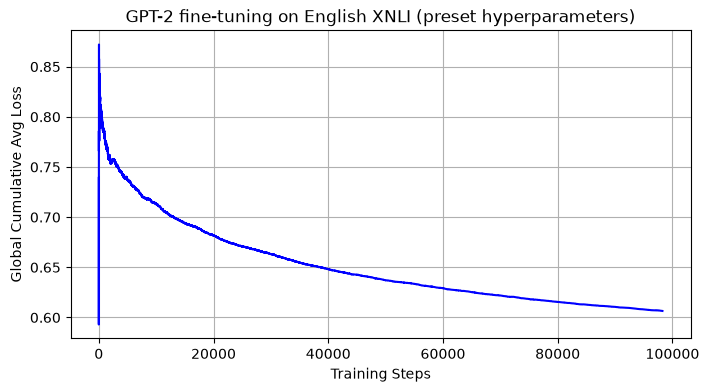

In [60]:
# Monitor the fine-tuning loss over time: the global average should drop quickly and then flatten
plt.figure(figsize=(8,4))
plt.plot(global_train_losses, label="Global Avg Train Loss", color='blue')
plt.xlabel("Training Steps")
plt.ylabel("Global Cumulative Avg Loss")
plt.title("GPT-2 fine-tuning on English XNLI (preset hyperparameters)")
plt.grid(True)
plt.show()


In [41]:
# Sanity check: after fine-tuning, the accuracy should be better than random guessing (33.33%)
# The accuracy we got is around 77.96% using whole training data and 1 epoch (Professor Comment)
# About our team, we got around 78.92% using the whole training data
SAVE_DIR = "best_model"
finetuned_model = GPT2Model(GPT2Config()).to(DEVICE)
finetuned_model.load_state_dict(torch.load(f"{SAVE_DIR}/model.pt"))
test_loader = DataLoader(test_dataset,shuffle=False,collate_fn=XNLIDataset.collate_fn)
acc, all_preds, all_labels = evaluate_gpt2_xnli(finetuned_model, tokenizer, test_loader, max_gen_length=1, device=DEVICE)

Generating: 100%|████████████████████████████████████████████████████████████████████████████| 5010/5010 [00:30<00:00, 163.33it/s]

Evaluation accuracy: 76.63%


In [43]:
# Record the baseline run (preset hyperparameters) so it can be compared with the runs below.
# Uses best_dev_acc / global_train_losses from the fine-tuning cell and acc from the test cell above.
baseline_results = {
    "run": "baseline",
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "weight_decay": WEIGHT_DECAY,
    "best_dev_acc": best_dev_acc,
    "test_acc": acc,
    "losses": global_train_losses,
}
print(f"Baseline | dev acc {best_dev_acc*100:.2f}% | test acc {acc*100:.2f}%")


Baseline | dev acc 78.15% | test acc 76.63%


## Hyperparameter Experiments
The preset hyperparameters (LR = 5e-5, batch size = 4, 1 epoch, weight decay = 0.01) give the baseline above.
Here we change some of them and repeat the whole pipeline. For a fair comparison, each run:
- reloads a **fresh** pretrained GPT-2 (not the one we just fine-tuned),
- saves its best checkpoint to its **own folder** (`best_model_<run_name>/model.pt`), so the baseline in `best_model/` is never overwritten,
- is evaluated on the same dev and test sets.

Each full run takes about as long as the baseline, so comment out entries in `EXPERIMENTS` if you are short on GPU time.


In [64]:
def finetune_and_evaluate(run_name, lr=5e-5, batch_size=4, epochs=1, weight_decay=0.01, correct_bias=True):
    """
    Re-run the Task 2 pipeline (fine-tune -> pick best epoch on dev -> evaluate on test)
    with a given set of hyperparameters. The training step is identical to TODO-9 above.

    Returns:
        dict: the hyperparameters, best dev accuracy, test accuracy and the loss curve.
    """
    save_dir = f"best_model_{run_name}"
    os.makedirs(save_dir, exist_ok=True)
    progress_path = f"{save_dir}/training_progress_{datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.json"

    # Start from the official pretrained weights every time
    run_model = GPT2Model.from_pretrained("gpt2").to(DEVICE)
    run_optimizer = AdamW(run_model.parameters(), lr=lr, weight_decay=weight_decay, correct_bias=correct_bias)
    run_train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=XNLIDataset.collate_fn)

    run_info = {"run": run_name, "lr": lr, "batch_size": batch_size, "epochs": epochs, "weight_decay": weight_decay, 
                "correct_bias": correct_bias, "total_steps": len(run_train_loader)*epochs, "epoch_history": []}
    run_losses = []
    total_loss, total_steps = 0.0, 0
    best_dev = -1.0

    for epoch in range(epochs):
        print(f"[{run_name}] Epoch {epoch+1}/{epochs}")
        run_model.train()
        loop = tqdm(run_train_loader, desc=f"Training {run_name}")
        for batch in loop:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            run_optimizer.zero_grad()
            hidden_states = run_model(input_ids=input_ids, attention_mask=attention_mask)['last_hidden_state']

            # Same next-token loss as TODO-9: shift by one, only the label token counts
            logits = run_model.hidden_state_to_token(hidden_states)
            loss = F.cross_entropy(
                logits[:, :-1, :].reshape(-1, logits.size(-1)),
                labels[:, 1:].reshape(-1),
                ignore_index=-100,
            )
            loss.backward()
            run_optimizer.step()

            total_loss += loss.item()
            total_steps += 1
            run_losses.append(total_loss / total_steps)
            loop.set_postfix({'avg_loss': f"{run_losses[-1]:.4f}"})

            # Record loss history on disk
            if total_steps % SAVE_EVERY == 0:
                save_json(progress_path, {**run_info, "steps_done": total_steps, "looses": run_losses})

        # Model selection on the dev set per epoches
        dev_acc, dev_preds, dev_labels = evaluate_gpt2_xnli(run_model, tokenizer, dev_loader, max_gen_length=1, device=DEVICE)
        run_info["epoch_history"].append({"epoch": epoch + 1, "step_dones": total_steps, "avg_loss": run_losses[-1], "dev_acc": dev_acc})
        run_results = {**run_info, "steps_done": total_steps, "dev_acc": dev_acc, "losses": run_losses}
        save_json(progress_path, run_results)
        if dev_acc > best_dev:
            best_dev = dev_acc
            torch.save(run_model.state_dict(), f"{save_dir}/model.pt")
            print(f"[{run_name}] New best model saved at {save_dir}/model.pt with dev accuracy {best_dev*100:.2f}%")

    # Reload the best checkpoint and report test accuracy
    run_model.load_state_dict(torch.load(f"{save_dir}/model.pt", map_location=DEVICE))
    test_acc, _, _ = evaluate_gpt2_xnli(run_model, tokenizer, test_loader, max_gen_length=1, device=DEVICE)

    # Free GPU memory before the next run
    del run_model, run_optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    results = {"run": run_name, "lr": lr, "batch_size": batch_size, "epochs": epochs, "weight_decay": weight_decay,
               "best_dev_acc": best_dev, "test_acc": test_acc, "losses": run_losses}
    return results


In [ ]:
# Each entry changes some of the preset hyperparameters (LR=5e-5, BS=4, epochs=1, WD=0.01)
EXPERIMENTS = [
    # Lower learning rate: smaller
    {"run_name": "lr2e-5", "lr": 2e-5},
    # Larger batch with a proportionally larger learning rate: less noisy gradients, 4x fewer optimizer steps
    {"run_name": "bs16_lr1e-4", "batch_size": 16, "lr": 1e-4},
]

hp_results = [baseline_results]
for exp in EXPERIMENTS:
    hp_results.append(finetune_and_evaluate(**exp))


[lr2e-5] Epoch 1/1


Training lr2e-5:  61%|███████████████████████████████████████████████████████████████████████████████▌                                                   | 59649/98176 [48:05<31:30, 20.38it/s, avg_loss=0.6161]

In [ ]:
# Compare all runs: accuracy table + loss curves
summary = pd.DataFrame([{k: v for k, v in r.items() if k != "losses"} for r in hp_results])
summary["best_dev_acc"] = (summary["best_dev_acc"] * 100).round(2)
summary["test_acc"] = (summary["test_acc"] * 100).round(2)
display(summary)

# x-axis = number of training examples seen, so runs with different batch sizes line up
plt.figure(figsize=(8,4))
for r in hp_results:
    examples_seen = np.arange(1, len(r["losses"]) + 1) * r["batch_size"]
    plt.plot(examples_seen, r["losses"], label=f'{r["run"]} (test {r["test_acc"]*100:.1f}%)')
plt.xlabel("Training examples seen")
plt.ylabel("Global Cumulative Avg Loss")
plt.title("Effect of hyperparameters on GPT-2 XNLI fine-tuning")
plt.legend()
plt.grid(True)
plt.show()


**Observations** (fill in after running):
- Effect of the lower learning rate:
- Effect of the larger batch size / learning rate:
- Which setting is best on dev vs. test, and why we think that is:


# Task 3 (Custom): 